# Glioma Grade Classification

**DSC 201 - Project 2**

Compare Logistic Regression, Random Forest, AdaBoost, and XGBoost using UCI dataset 759. Grade 0 means LGG and grade 1 means GBM. This is a course project, not a medical diagnostic tool.


## Step 2: Load and inspect the data

Check the actual data before choosing any cleaning steps. These functions come from main.py so we do not maintain two copies of the same code. Run this notebook from the repository folder. The first download needs internet access; later runs use the saved UCI copy.


In [1]:
from main import (load_data, inspect_data, plot_eda, prepare_data, split_data,
                  build_models, run_experiments, summarize_results, plot_model_results)
from pathlib import Path
import pandas as pd


In [2]:
# Use the saved UCI copy, or download dataset 759 if the CSV is missing.
# To download it again, use load_data(refresh=True).
X, y = load_data()


In [3]:
# Show rows, dimensions, types, statistics, missing values, duplicates,
# class counts, and the actual category codes. No cleaning happens here.
inspect_data(X, y)


FIRST FIVE ROWS
 Gender  Age_at_diagnosis  Race  IDH1  TP53  ATRX  PTEN  EGFR  CIC  MUC16  PIK3CA  NF1  PIK3R1  FUBP1  RB1  NOTCH1  BCOR  CSMD3  SMARCA4  GRIN2A  IDH2  FAT4  PDGFRA  Grade
      0             51.30 white     1     0     0     0     0    0      0       1    0       0      1    0       0     0      0        0       0     0     0       0      0
      0             38.72 white     1     0     0     0     0    1      0       0    0       0      0    0       0     0      0        0       0     0     0       0      0
      0             35.17 white     1     1     1     0     0    0      0       0    0       0      0    0       0     0      0        0       0     0     0       0      0
      1             32.78 white     1     1     1     0     0    0      1       0    0       1      0    0       0     0      0        0       0     0     1       0      0
      0             31.51 white     1     1     1     0     0    0      0       0    0       0      0    0       0     0    

## What the inspection shows

- There are 839 rows and 23 input features: 20 gene features and 3 clinical features.
- Grade contains 487 LGG cases (58.05%) and 352 GBM cases (41.95%).
- There are no missing values in the supplied file. We do not need to fill any values at this stage.
- The 20 gene features and Gender contain 0 and 1. Age is numerical, ranging from 14.42 to 89.29 years.
- Race contains four text labels, so it will need encoding before modeling. Its supplied dictionary describes number codes, which differ from the text labels actually loaded.
- One full record is repeated. We have kept it for now because matching features and grade do not prove that the same patient appears twice. The preprocessing step below explains our decision about this record.

At this inspection stage, no rows have been changed. The later preprocessing step removes one repeated record. The completed models and results appear later in this notebook.


## Step 3: Explore the data

These plots describe the original 839 records, before removing the repeated record. Each chart is saved in results/figures/. Plots help us understand the data; they do not prove that a model will predict well.


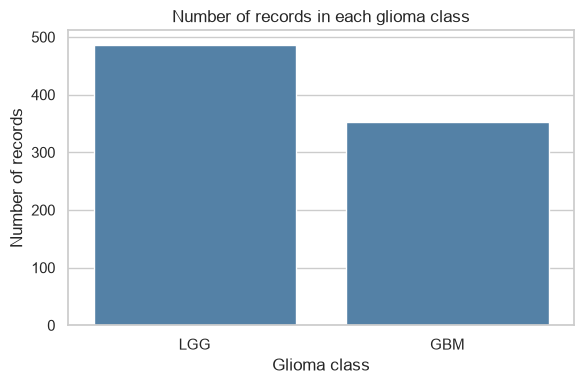

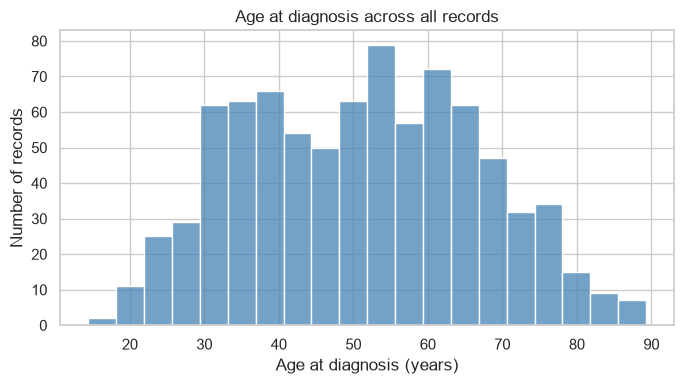

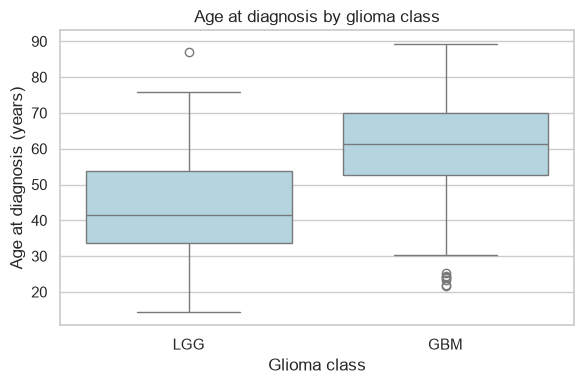

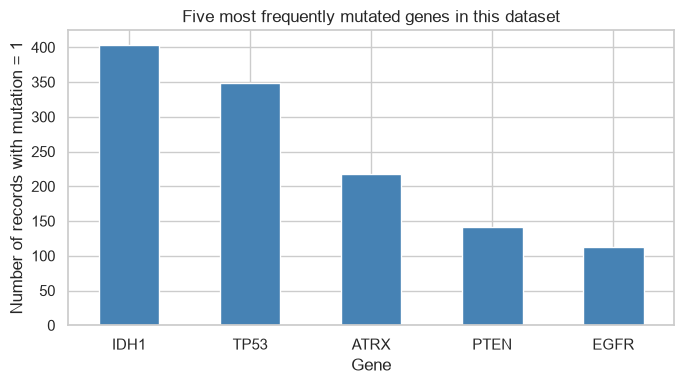

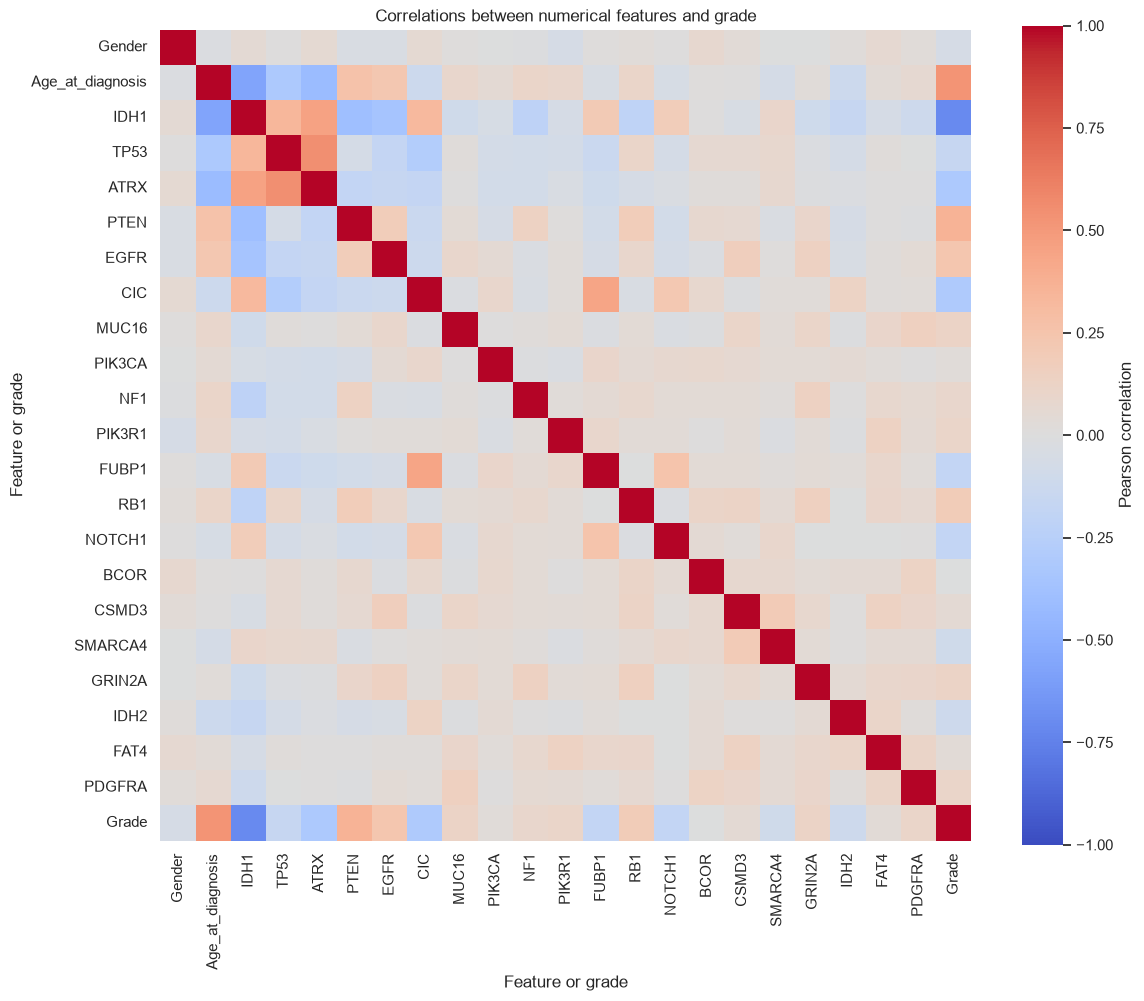

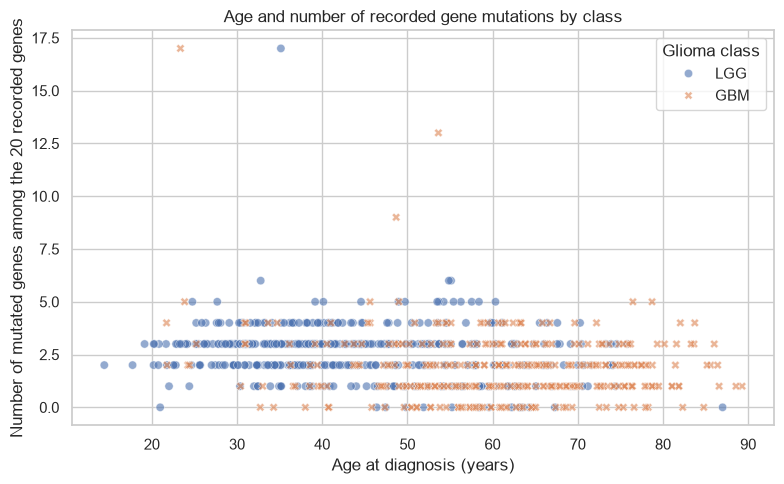

In [4]:
plot_eda(X, y)


### What the six plots show

1. **Class counts:** LGG has 487 records and GBM has 352. The groups are not exactly balanced.
2. **Age histogram:** Ages range from about 14 to 89. This shows how many people fall into each age range.
3. **Age by class:** The median age is about 42 for LGG and 61 for GBM. GBM cases tend to be older in this sample, but the age ranges overlap. Age alone cannot perfectly separate the classes.
4. **Mutation counts:** IDH1, TP53, ATRX, PTEN, and EGFR are the five most commonly mutated genes in this file. These are the genes shown in this chart, not a claim that they are the best predictors. All 20 gene features remain available for modeling.
5. **Correlation heatmap:** Colors show how numerical features and grade vary together. Race is excluded because its labels have no numerical order. A correlation is not proof of cause and effect. Grade is included in this descriptive chart but is never an input to a model.
6. **Scatter plot:** Each point shows a record's age and total mutations among the 20 genes. The colors and marker shapes show LGG or GBM. Overlapping points show why these two values do not give a perfect class rule. Mutation count is used only for this chart.


## Step 4: Basic preprocessing

- **Repeated record:** Remove one exact repeated full record before splitting. We cannot prove that it is the same patient without IDs. Keeping only the first copy avoids identical records appearing in both training and test sets. This is a stated choice and could remove a different person who happened to have matching values. The raw CSV stays unchanged.
- **Missing values:** None are present, so we do not fill in any values.
- **Age:** Check the usual 1.5-times-IQR rule. It flags no unusual ages in the prepared data, so keep all ages. This rule is a simple data check, not a medical judgment.
- **Race:** Make a separate yes/no column for each UCI category. This avoids pretending that one race is numerically higher than another. This fixed category list does not use Grade or learn anything from test outcomes.
- **Other columns:** The gene features and Gender already use 0 and 1.


In [5]:
X_ready, y_ready = prepare_data(X, y)
print(X_ready.head().to_string(index=False))


Exact repeated records removed: 1
Age IQR limits: 0.95 to 99.93 years
Ages flagged by the IQR rule: 0
No ages were removed or changed.
Prepared input dimensions: (838, 26)
Prepared class counts:
Grade
0    486
1    352
Name: count, dtype: int64
 Gender  Age_at_diagnosis  IDH1  TP53  ATRX  PTEN  EGFR  CIC  MUC16  PIK3CA  NF1  PIK3R1  FUBP1  RB1  NOTCH1  BCOR  CSMD3  SMARCA4  GRIN2A  IDH2  FAT4  PDGFRA  Race_white  Race_black or african american  Race_asian  Race_american indian or alaska native
      0             51.30     1     0     0     0     0    0      0       1    0       0      1    0       0     0      0        0       0     0     0       0           1                               0           0                                      0
      0             38.72     1     0     0     0     0    1      0       0    0       0      0    0       0     0      0        0       0     0     0       0           1                               0           0                                 

### Stratified training and test sets

Reserve 20% of the prepared records for testing. Stratification keeps similar class proportions in both sets. The fixed seed makes this example repeatable. Race encoding gives 26 numeric input columns from the original 23 features; it does not add new survey information.

The split function also has an optional normalize=True setting. It learns the scaling values from training data only. For later hyperparameter tuning, we will use normalize=False here and put scaling inside each model pipeline where needed. That will also keep validation folds separate during cross-validation. Tree models do not need scaling.


In [6]:
X_train, X_test, y_train, y_test = split_data(
    X_ready, y_ready, random_state=42, normalize=False)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print(pd.DataFrame({"Training": y_train.value_counts(),
                    "Testing": y_test.value_counts()}).sort_index())


Training shape: (670, 26)
Testing shape: (168, 26)
       Training  Testing
Grade                   
0           389       97
1           281       71


## Step 5: The four models and tuning

- **Logistic Regression** learns a weighted rule for predicting GBM. Its inputs are standardized inside the pipeline.
- **Random Forest** combines many decision trees. Different trees use different samples and feature choices.
- **AdaBoost** adds small decision trees one at a time, giving more attention to cases that were difficult to classify.
- **XGBoost** adds trees to improve earlier predictions, with settings that limit how complicated the trees become.

All four use small GridSearchCV grids and the same five shuffled stratified folds. We tune by binary F1 with GBM (1) as the positive class. The test set is not used to choose settings. Trees do not need scaling. The Logistic Regression scaler is fitted inside each CV training fold.

| Model | Parameter grid | Combinations |
|---|---|---|
| Logistic Regression | C = 0.1, 1, 10 | 3 |
| Random Forest | trees = 50, 100; max depth = 5, unlimited | 4 |
| AdaBoost | trees = 30, 60; learning rate = 0.1, 0.5 | 4 |
| XGBoost | trees = 50; max depth = 2, 3; learning rate = 0.05, 0.1 | 4 |

XGBoost's tree count is fixed to keep the grid small; depth and learning rate are tuned. Each search refits the best pipeline on its full training split automatically.


In [7]:
models, grids = build_models(seed=100)
for name in models:
    print(name, grids[name])


Logistic Regression {'model__C': [0.1, 1, 10]}
Random Forest {'model__n_estimators': [50, 100], 'model__max_depth': [5, None]}
AdaBoost {'model__n_estimators': [30, 60], 'model__learning_rate': [0.1, 0.5]}
XGBoost {'model__n_estimators': [50], 'model__max_depth': [2, 3], 'model__learning_rate': [0.05, 0.1]}


## Step 6: Thirty fair comparisons

For each seed from 100 to 129, all four models use the same stratified 80/20 split and five CV folds. The complete search is repeated inside every new training set. We record test accuracy, precision, recall, and F1, plus training scores for context.

We also run the optional comparison using only the 20 recorded gene features. It uses the same people, seeds, and CV method. These genes were selected by the dataset creators; we do not randomly choose a subset.

The cell below loads the completed results by default. Set RUN_EXPERIMENTS to True to repeat all training. Running main.py also repeats the experiments. No training is skipped when reproducing the full experiment; reading CSVs here simply avoids rerunning it every time you view the notebook.


In [8]:
RUN_EXPERIMENTS = False
gene_columns = X.columns.drop(["Gender", "Age_at_diagnosis", "Race"])
if RUN_EXPERIMENTS:
    results, representative = run_experiments(X_ready, y_ready, gene_columns, n_repeats=30)
else:
    results = pd.read_csv("results/model_results.csv")
    representative = {}
    for name in models:
        filename = name.lower().replace(" ", "_") + "_seed100_predictions.csv"
        representative[name] = pd.read_csv(Path("results") / filename)

# There should be 30 runs for each of four models in both feature comparisons.
print(results.groupby(["Feature_set", "Model"]).size())
print("Saved result rows:", len(results))
display(results.head(8))


Feature_set     Model              
All features    AdaBoost               30
                Logistic Regression    30
                Random Forest          30
                XGBoost                30
Mutations only  AdaBoost               30
                Logistic Regression    30
                Random Forest          30
                XGBoost                30
dtype: int64
Saved result rows: 240


,Feature_set,Model,Replicate,Seed,Best_CV_F1,Best_parameters,Accuracy,Training_Accuracy,Precision,Training_Precision,Recall,Training_Recall,F1,Training_F1
0,All features,Logistic Regression,1,100,0.859476,{'model__C': 10},0.869048,0.880597,0.826667,0.817035,0.873239,0.921708,0.849315,0.866221
1,All features,Random Forest,1,100,0.849781,"{'model__max_depth': 5, 'model__n_estimators':...",0.845238,0.882090,0.816901,0.832237,0.816901,0.900356,0.816901,0.864957
2,All features,AdaBoost,1,100,0.853529,"{'model__learning_rate': 0.5, 'model__n_estima...",0.869048,0.871642,0.818182,0.791045,0.887324,0.943060,0.851351,0.860390
3,All features,XGBoost,1,100,0.859791,"{'model__learning_rate': 0.05, 'model__max_dep...",0.863095,0.870149,0.815789,0.788690,0.873239,0.943060,0.843537,0.858995
4,Mutations only,Logistic Regression,1,100,0.863204,{'model__C': 0.1},0.857143,0.882090,0.813333,0.807927,0.859155,0.943060,0.835616,0.870279
5,Mutations only,Random Forest,1,100,0.857164,"{'model__max_depth': 5, 'model__n_estimators':...",0.875000,0.882090,0.820513,0.811728,0.901408,0.935943,0.859060,0.869421
6,Mutations only,AdaBoost,1,100,0.859791,"{'model__learning_rate': 0.5, 'model__n_estima...",0.869048,0.870149,0.818182,0.788690,0.887324,0.943060,0.851351,0.858995
7,Mutations only,XGBoost,1,100,0.861233,"{'model__learning_rate': 0.1, 'model__max_dept...",0.863095,0.874627,0.815789,0.795796,0.873239,0.943060,0.843537,0.863192


## Step 7: Results across the 30 repetitions

Each summary row gives the mean, sample standard deviation (SD), minimum, and maximum of 30 held-out test scores. SD describes changes across splits, not uncertainty across 30 independent studies. The test groups overlap. Training scores are kept separately and are not presented as test scores.


In [9]:
summary = summarize_results(results)
main_summary = summary[summary["Feature_set"] == "All features"]
display(main_summary.round(4))
# A compact comparison table: mean test score for each metric.
display(main_summary.pivot(index="Model", columns="Metric", values="Mean").round(4))


,Feature_set,Model,Metric,Mean,SD,Minimum,Maximum
0,All features,Logistic Regression,Accuracy,0.8706,0.0211,0.8274,0.9167
1,All features,Logistic Regression,Precision,0.8078,0.0329,0.7500,0.8701
2,All features,Logistic Regression,Recall,0.9131,0.0312,0.8592,0.9577
3,All features,Logistic Regression,F1,0.8566,0.0219,0.8129,0.9054
4,All features,Random Forest,Accuracy,0.8655,0.0194,0.8155,0.8988
5,All features,Random Forest,Precision,0.7996,0.0284,0.7326,0.8493
6,All features,Random Forest,Recall,0.9117,0.0327,0.8169,0.9577
7,All features,Random Forest,F1,0.8514,0.0208,0.8025,0.8859
8,All features,AdaBoost,Accuracy,0.8633,0.0205,0.8274,0.9048
9,All features,AdaBoost,Precision,0.7860,0.0303,0.7283,0.8533


Metric,Accuracy,F1,Precision,Recall
Model,,,,
AdaBoost,0.8633,0.8523,0.7860,0.9319
Logistic Regression,0.8706,0.8566,0.8078,0.9131
Random Forest,0.8655,0.8514,0.7996,0.9117
XGBoost,0.8641,0.8517,0.7916,0.9230


### Model comparison charts

- **Bar charts:** mean test scores with sample SD error bars.
- **Box plots:** spread of each test metric across the 30 splits.
- **Confusion matrices:** only replicate 1 (seed 100), picked in advance. Rows show actual classes, and columns show predicted classes. These 168 test records are not the full 30-run sample.
- **Summary heatmap:** mean test scores in a compact table of colors.
- **Secondary bar chart:** mean GBM F1 for all features versus mutations only on the same splits.

Every chart is saved in results/figures/ for the report and slides.


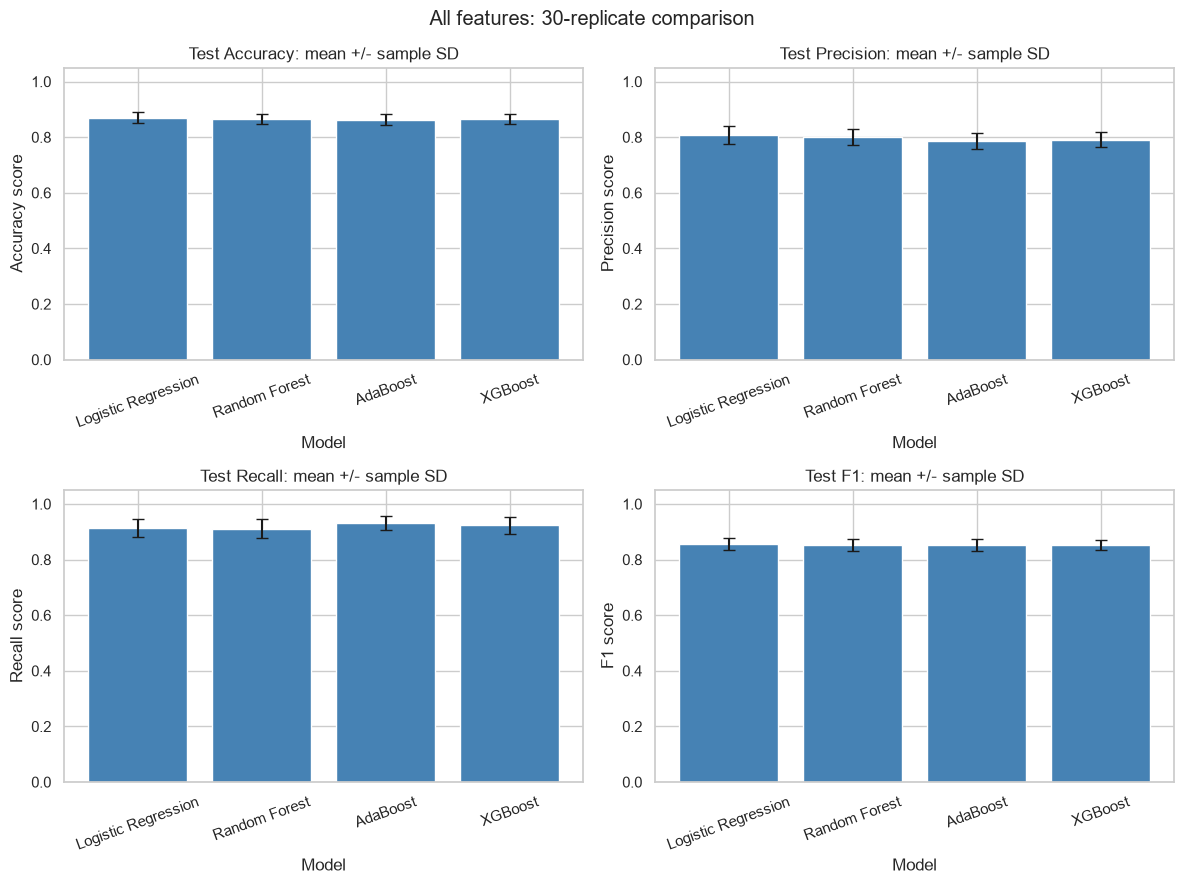

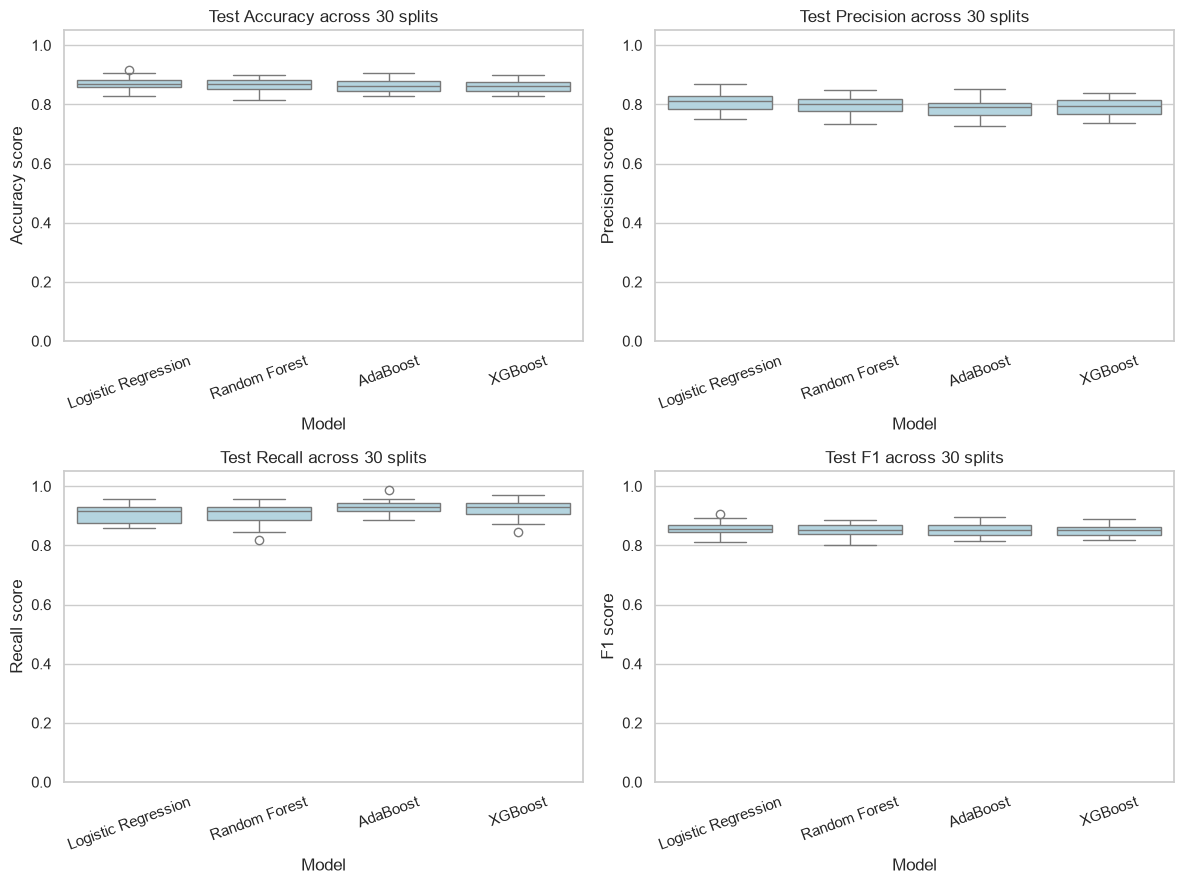

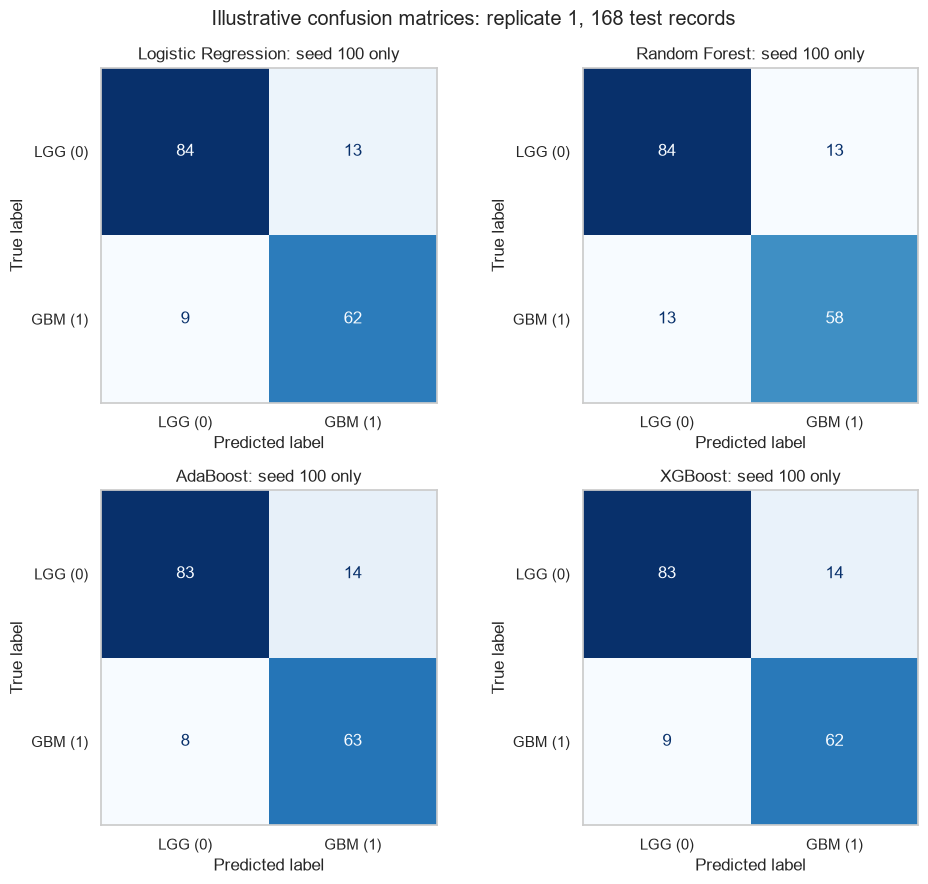

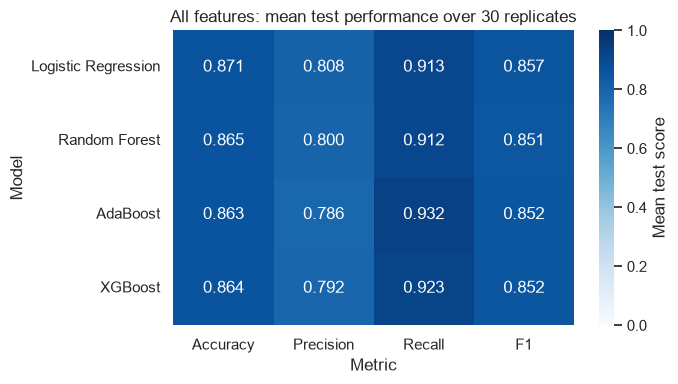

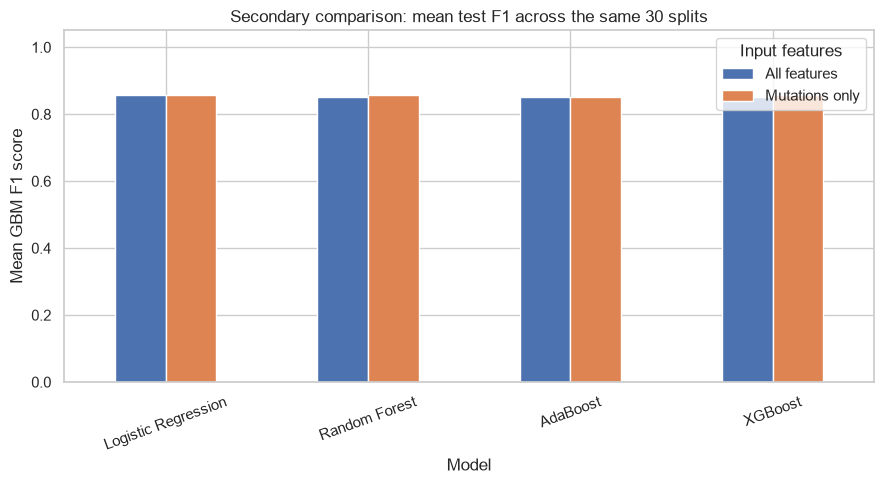

In [10]:
plot_model_results(results, summary, representative)


## Step 8: Clinical and mutation features

The main comparison uses all 23 original features (26 numeric columns after Race encoding). The secondary comparison uses the 20 gene features only. Compare means and variability rather than treating a small difference as proof that one feature set is always better.


In [11]:
f1_summary = summary[summary["Metric"] == "F1"]
display(f1_summary.round(4))
comparison = f1_summary.pivot(index="Model", columns="Feature_set", values="Mean")
comparison["All minus mutations"] = comparison["All features"] - comparison["Mutations only"]
display(comparison.round(4))


,Feature_set,Model,Metric,Mean,SD,Minimum,Maximum
3,All features,Logistic Regression,F1,0.8566,0.0219,0.8129,0.9054
7,All features,Random Forest,F1,0.8514,0.0208,0.8025,0.8859
11,All features,AdaBoost,F1,0.8523,0.0201,0.8153,0.8947
15,All features,XGBoost,F1,0.8517,0.0187,0.8176,0.8889
19,Mutations only,Logistic Regression,F1,0.8578,0.0205,0.8205,0.8919
23,Mutations only,Random Forest,F1,0.8563,0.0239,0.8101,0.9007
27,Mutations only,AdaBoost,F1,0.8517,0.0177,0.8153,0.8831
31,Mutations only,XGBoost,F1,0.8563,0.0180,0.8250,0.8947


Feature_set,All features,Mutations only,All minus mutations
Model,,,
AdaBoost,0.8523,0.8517,0.0006
Logistic Regression,0.8566,0.8578,-0.0012
Random Forest,0.8514,0.8563,-0.0049
XGBoost,0.8517,0.8563,-0.0046


## Findings and written deliverables

Logistic Regression had the highest all-feature mean test F1 (0.8566 +/- 0.0219) and mean accuracy (0.8706 +/- 0.0211). Its F1 lead over AdaBoost was only about 0.0043, so this is not proof that it is always better. Adding clinical features raised mean F1 only for AdaBoost, by about 0.0006; the other three models had slightly higher mean F1 with mutation features alone.

These results describe this dataset and the selected grids. Test groups overlap, some demographic groups are small, and there was no external validation. This is an educational comparison, not a medical decision tool.

The full report and seven-slide outline with speaker notes are saved in report/project_report.md and report/presentation_outline.md. They use the completed results from this project.


## Data source

Tasci, E., Camphausen, K., Krauze, A. V., and Zhuge, Y. (2022). *Glioma Grading Clinical and Mutation Features*. UCI Machine Learning Repository. https://doi.org/10.24432/C5R62J

The downloaded variable definitions are saved in data/variable_dictionary.csv.
